# Questão 1 — versão revisada com auditoria

O notebook original e seus resultados estão preservados. Esta revisão acrescenta diagnósticos e um experimento de sensibilidade. Execute as células em ordem, na pasta deste notebook.

Por padrão, reconstruímos as melhores soluções pelas seeds do ZIP, conferindo W e Silhouette. Isso reaproveita a seleção das 100 execuções já realizadas, sem afirmar que as executamos novamente. Para repetir o grid completo, defina `REUTILIZAR_ZIP=False`.

A comparação de pré-processamentos roda 100 execuções válidas por par para dados originais e log1p+StandardScaler; StandardScaler reaproveita o grid conferido. As saídas ficam em `resultados_questao1_revisada/`. Os rótulos oficiais continuam sendo os do experimento original até a orientação do professor.



# Projeto AM 2026.2 — Questão 1
## Double K-means aplicado ao Spambase

Este notebook implementa a Questão 1 do projeto:

1. carregar o `spambase.data`;
2. separar atributos `X` e classe original `y`;
3. padronizar os atributos;
4. executar Double K-means para:
   - \(K \in \{2,3,4\}\);
   - \(H \in \{1,\ldots,K\}\);
   - **100 execuções válidas** por par \((K,H)\);
5. selecionar, para cada par, a execução com **menor função objetivo**;
6. calcular Silhouette da partição de objetos selecionada;
7. escolher \((K^\*,H^\*)\) pela maior Silhouette;
8. calcular Adjusted Rand Index contra a classe original;
9. mostrar:
   - matriz de protótipos \(G\);
   - matriz de contingência entre clusters e classes originais;
   - função objetivo × iterações;
   - Silhouette × \((K,H)\);
10. exportar os rótulos necessários para a Questão 2.

> **Importante:** a classe original não participa do clustering. Ela só é usada
> posteriormente para ARI e matriz de contingência.



## 1. Bibliotecas e configuração

A implementação do algoritmo foi colocada também em `double_kmeans.py`
para facilitar o compartilhamento com o grupo.


In [ ]:
# Execute se precisar instalar as dependências no ambiente do notebook.
%pip install numpy pandas matplotlib scikit-learn


In [1]:


from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score,
)

import sys
sys.path.insert(0, str((Path(".") / ".." / "src").resolve()))
from double_kmeans import double_kmeans

RANDOM_BASE_SEED = 42
N_RESTARTS = 100
MAX_ITER = 200

BASE_DIR = Path(".")
DATA_PATH = BASE_DIR / ".." / ".." / "data" / "raw" / "spambase.data"
NAMES_PATH = BASE_DIR / ".." / ".." / "data" / "raw" / "spambase.names"
OUTPUT_DIR = BASE_DIR / "resultados_questao1_revisada"
REUTILIZAR_ZIP = True
ZIP_RESULTS = BASE_DIR / "resultados_originais_zip"
OUTPUT_DIR.mkdir(exist_ok=True)

print("Pasta de saída:", OUTPUT_DIR.resolve())


Pasta de saída: C:\Users\Leticia\.codex\.chatgpt-projects\g-p-6a8591c406b48191ad22905b26a0c44a\questao1_revisada\resultados_questao1_revisada



## 2. Leitura do Spambase

O arquivo possui **57 atributos preditores** e uma última coluna com a
classe original:

- `0`: non-spam;
- `1`: spam.

Vamos extrair também os nomes das variáveis a partir de `spambase.names`.


In [2]:

def load_feature_names(names_path: Path):
    names = []
    with open(names_path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()
            if ":" in line and "continuous" in line.lower():
                names.append(line.split(":", 1)[0].strip())
    return names

feature_names = load_feature_names(NAMES_PATH)

raw = pd.read_csv(DATA_PATH, header=None)

n_features = raw.shape[1] - 1
assert n_features == 57, f"Esperava 57 atributos, encontrei {n_features}."
assert len(feature_names) == 57, (
    f"Esperava 57 nomes em spambase.names, encontrei {len(feature_names)}."
)

X_df = raw.iloc[:, :-1].copy()
X_df.columns = feature_names

y_original = raw.iloc[:, -1].astype(int).to_numpy()
X_original = X_df.to_numpy(dtype=float)

print("Shape de X:", X_original.shape)
print("Número de classes originais:", np.unique(y_original))
print("\nDistribuição da classe original:")
print(pd.Series(y_original).value_counts().sort_index())


Shape de X: (4601, 57)
Número de classes originais: [0 1]

Distribuição da classe original:
0    2788
1    1813
Name: count, dtype: int64



## 3. Padronização

O Double K-means minimiza uma função baseada em **distâncias quadráticas**.
Como os atributos do Spambase têm escalas bastante diferentes, usaremos
padronização z-score:

\[
z_{ij} = \frac{x_{ij}-\mu_j}{\sigma_j}.
\]

A mesma matriz padronizada será usada tanto no Double K-means quanto na
Silhouette, garantindo consistência entre o espaço no qual os clusters são
obtidos e aquele no qual são avaliados.

> No relatório, registre explicitamente esta decisão metodológica.


In [3]:

scaler = StandardScaler()
X = scaler.fit_transform(X_original)

print("Médias aproximadas após padronização:")
print(np.round(X.mean(axis=0)[:5], 6))

print("\nDesvios padrão aproximados:")
print(np.round(X.std(axis=0)[:5], 6))


Médias aproximadas após padronização:
[0. 0. 0. 0. 0.]

Desvios padrão aproximados:
[1. 1. 1. 1. 1.]



## 4. Função para as 100 execuções de cada \((K,H)\)

A ordem do experimento é:

\[
100\ \text{execuções}
\rightarrow
\text{selecionar menor } W
\rightarrow
\text{calcular Silhouette}.
\]

Ou seja, **não selecionamos a maior Silhouette entre as 100 execuções**.

O Double K-means pode eventualmente gerar um cluster vazio em uma
inicialização. Nesse caso, descartamos essa inicialização e continuamos até
obter exatamente 100 execuções válidas.


In [4]:

def run_restarts(X, K, H, n_restarts=100, base_seed=2026, max_iter=200):
    best = None
    valid_runs = 0
    attempts = 0
    invalid_runs = 0

    objectives = []

    # A fórmula gera seeds diferentes e reproduzíveis para cada (K,H).
    seed = base_seed + 10000 * K + 1000 * H

    while valid_runs < n_restarts:
        if attempts >= 10000:
            raise RuntimeError(f"Limite de tentativas atingido em K={K}, H={H}; não usar grid incompleto.")
        result = double_kmeans(
            X=X,
            K=K,
            H=H,
            seed=seed,
            max_iter=max_iter,
        )

        attempts += 1

        if result is None:
            invalid_runs += 1
            seed += 1
            continue

        valid_runs += 1
        objectives.append(result.objective)

        if best is None or result.objective < best.objective:
            best = result

        seed += 1

    return {
        "best": best,
        "valid_runs": valid_runs,
        "attempts": attempts,
        "invalid_runs": invalid_runs,
        "all_final_objectives": np.asarray(objectives),
    }



## 5. Executar toda a grade experimental

Serão avaliados os nove pares:

\[
(2,1),(2,2),
(3,1),(3,2),(3,3),
(4,1),(4,2),(4,3),(4,4).
\]

Como cada par exige 100 execuções válidas, teremos **900 execuções válidas**
do algoritmo.

> Esta é a célula mais demorada do notebook.


In [5]:
if REUTILIZAR_ZIP:
    results_df = pd.read_csv(ZIP_RESULTS / "resultados_KH.csv")
    best_runs = {}
    for row in results_df.itertuples():
        best = double_kmeans(X, int(row.K), int(row.H), int(row.best_seed), MAX_ITER)
        assert best is not None, "Seed do ZIP gerou partição inválida."
        assert np.isclose(best.objective, row.best_objective_W, rtol=1e-9, atol=1e-5), "W não reproduzido."
        sil = silhouette_score(X, best.object_labels)
        assert np.isclose(sil, row.silhouette, atol=1e-8), "Silhouette não reproduzida."
        best_runs[(int(row.K), int(row.H))] = best
    winner = results_df.loc[results_df.silhouette.idxmax()]
    saved = pd.read_csv(ZIP_RESULTS / "spambase_com_clusters.csv")
    np.testing.assert_allclose(saved[feature_names].to_numpy(), X_original)
    assert np.array_equal(saved.y_original.to_numpy(), y_original)
    assert adjusted_rand_score(saved.y_double_kmeans, best_runs[(int(winner.K), int(winner.H))].object_labels) == 1
    results_df.to_csv(OUTPUT_DIR / "resultados_KH.csv", index=False)
    display(results_df)
else:
    
    grid_rows = []
    best_runs = {}
    
    for K in [2, 3, 4]:
        for H in range(1, K + 1):
            print(f"Executando K={K}, H={H}...")
    
            experiment = run_restarts(
                X=X,
                K=K,
                H=H,
                n_restarts=N_RESTARTS,
                base_seed=RANDOM_BASE_SEED,
                max_iter=MAX_ITER,
            )
    
            best = experiment["best"]
    
            # Silhouette somente APÓS selecionar a execução de menor W.
            sil = silhouette_score(
                X,
                best.object_labels,
                metric="euclidean",
            )
    
            best_runs[(K, H)] = best
    
            grid_rows.append({
                "K": K,
                "H": H,
                "best_objective_W": best.objective,
                "silhouette": sil,
                "best_seed": best.seed,
                "n_iterations_best": best.n_iter,
                "valid_runs": experiment["valid_runs"],
                "invalid_attempts": experiment["invalid_runs"],
                "total_attempts": experiment["attempts"],
            })
    
    results_df = pd.DataFrame(grid_rows).sort_values(["K", "H"]).reset_index(drop=True)
    
    display(results_df)
    
    results_df.to_csv(
        OUTPUT_DIR / "resultados_KH.csv",
        index=False
    )


   K  H  best_objective_W  ...  valid_runs  invalid_attempts  total_attempts
0  2  1     256513.748244  ...         100                 0             100
1  2  2     244486.698350  ...         100                 0             100
2  3  1     254414.012879  ...         100                 0             100
3  3  2     239373.657682  ...         100                 0             100
4  3  3     234585.866367  ...         100                23             123
5  4  1     253278.679517  ...         100                 1             101
6  4  2     233358.702214  ...         100                 5             105
7  4  3     228516.443669  ...         100                 9             109
8  4  4     227234.111517  ...         100                36             136

[9 rows x 9 columns]


## 6. Verificações de sanidade

Para cada melhor execução:

- existem exatamente \(K\) clusters de objetos;
- existem exatamente \(H\) clusters de variáveis;
- a função objetivo é não crescente ao longo das iterações.

Esses testes ajudam a detectar erros de implementação antes de interpretar
os resultados.


In [6]:

checks = []

for (K, H), result in best_runs.items():
    n_obj_clusters = np.unique(result.object_labels).size
    n_var_clusters = np.unique(result.variable_labels).size

    diffs = np.diff(result.objective_history)
    monotonic = bool(np.all(diffs <= 1e-7))

    checks.append({
        "K": K,
        "H": H,
        "object_clusters_found": n_obj_clusters,
        "variable_clusters_found": n_var_clusters,
        "objective_non_increasing": monotonic,
    })

checks_df = pd.DataFrame(checks)
display(checks_df)

assert (checks_df["object_clusters_found"] == checks_df["K"]).all()
assert (checks_df["variable_clusters_found"] == checks_df["H"]).all()
assert checks_df["objective_non_increasing"].all()

print("Todas as verificações passaram.")


Todas as verificações passaram.


   K  H  ...  variable_clusters_found  objective_non_increasing
0  2  1  ...                        1                      True
1  2  2  ...                        2                      True
2  3  1  ...                        1                      True
3  3  2  ...                        2                      True
4  3  3  ...                        3                      True
5  4  1  ...                        1                      True
6  4  2  ...                        2                      True
7  4  3  ...                        3                      True
8  4  4  ...                        4                      True

[9 rows x 5 columns]


## 7. Plot Silhouette × \((K,H)\) e escolha de \(K^\*\)

O enunciado define:

\[
K^\* = \arg\max_{K,H} Sil((K,H)).
\]

Para recuperar exatamente a solução vencedora, guardaremos também \(H^\*\):

\[
(K^\*,H^\*) = \arg\max_{K,H} Sil(K,H).
\]


K* = 2
H* = 2
Silhouette máxima = 0.659631
W da melhor execução = 244486.698350
Seed da melhor execução = 22042


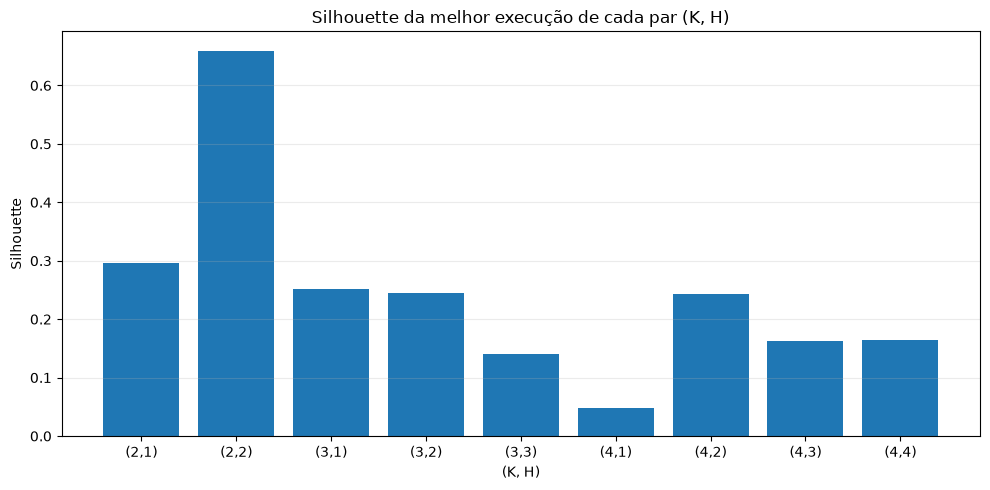

In [7]:

best_row = results_df.loc[results_df["silhouette"].idxmax()]

K_star = int(best_row["K"])
H_star = int(best_row["H"])
best_solution = best_runs[(K_star, H_star)]

print(f"K* = {K_star}")
print(f"H* = {H_star}")
print(f"Silhouette máxima = {best_row['silhouette']:.6f}")
print(f"W da melhor execução = {best_row['best_objective_W']:.6f}")
print(f"Seed da melhor execução = {int(best_row['best_seed'])}")

labels_kstar = best_solution.object_labels.copy()

plot_df = results_df.copy()
plot_df["KH"] = [
    f"({int(k)},{int(h)})"
    for k, h in zip(plot_df["K"], plot_df["H"])
]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(plot_df["KH"], plot_df["silhouette"])
ax.set_xlabel("(K, H)")
ax.set_ylabel("Silhouette")
ax.set_title("Silhouette da melhor execução de cada par (K, H)")
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "silhouette_KH.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()



## 8. Adjusted Rand Index — partição encontrada × classes originais

O **Adjusted Rand Index (ARI)** compara duas partições sem exigir
correspondência entre os números usados como rótulos.

Portanto, se o Double K-means chamar um cluster de `0` e a classe equivalente
no dataset estiver codificada como `1`, essa simples troca de nomes não é
penalizada.

O ARI será usado **somente após a escolha de \(K^\*\)**.


In [8]:

ari = adjusted_rand_score(y_original, labels_kstar)

print(f"Adjusted Rand Index = {ari:.6f}")

with open(
    OUTPUT_DIR / "resumo_resultado_final.txt",
    "w",
    encoding="utf-8",
) as f:
    f.write(f"K* = {K_star}\n")
    f.write(f"H* = {H_star}\n")
    f.write(f"Silhouette = {best_row['silhouette']:.10f}\n")
    f.write(f"Best objective W = {best_solution.objective:.10f}\n")
    f.write(f"Best seed = {best_solution.seed}\n")
    f.write(f"Adjusted Rand Index = {ari:.10f}\n")


Adjusted Rand Index = -0.004950



### Como comentar o ARI

Use o valor obtido pelo notebook, mas mantenha esta interpretação:

- \(ARI=1\): concordância perfeita entre as partições;
- \(ARI \approx 0\): concordância próxima ao esperado ao acaso;
- valores negativos: concordância abaixo do esperado sob o modelo de
  referência do índice.

Um ARI baixo **não implica automaticamente que o clustering esteja errado**.
O Double K-means é não supervisionado e minimiza a heterogeneidade dos blocos;
ele não recebe `spam/non-spam` durante o treinamento. Logo, a estrutura
geométrica encontrada pode ser diferente da partição a priori.



## 9. Matriz de protótipos \(G\)

Para a solução vencedora, \(G\) possui dimensão:

\[
K^\* \times H^\*.
\]

Cada elemento \(g_{kh}\) é a média do bloco formado pelo grupo de objetos
\(k\) e pelo grupo de variáveis \(h\).


In [9]:

G_df = pd.DataFrame(
    best_solution.G,
    index=[f"obj_cluster_{k}" for k in range(K_star)],
    columns=[f"var_cluster_{h}" for h in range(H_star)],
)

display(G_df)

G_df.to_csv(
    OUTPUT_DIR / "matriz_prototipos_G.csv"
)


               var_cluster_0  var_cluster_1
obj_cluster_0       6.861185      -0.144405
obj_cluster_1      -0.051080       0.001075


## 10. Matriz de contingência: clusters × classe a priori

Se \(K^\* > 2\), a matriz não será quadrada, pois a classe original possui
duas categorias enquanto o clustering terá \(K^\*\) grupos.

Nesse contexto, "matriz de confusão" do enunciado é melhor interpretada
matematicamente como uma **matriz de contingência** entre as duas partições.


classe_original           0     1
cluster_double_kmeans            
0                        34     0
1                      2754  1813

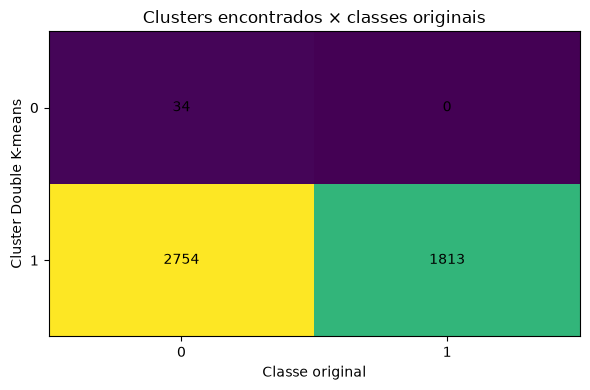

In [10]:

contingency = pd.crosstab(
    pd.Series(labels_kstar, name="cluster_double_kmeans"),
    pd.Series(y_original, name="classe_original"),
)

display(contingency)

contingency.to_csv(
    OUTPUT_DIR / "matriz_contingencia.csv"
)

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(contingency.values, aspect="auto")

ax.set_xticks(np.arange(contingency.shape[1]))
ax.set_xticklabels(contingency.columns)

ax.set_yticks(np.arange(contingency.shape[0]))
ax.set_yticklabels(contingency.index)

ax.set_xlabel("Classe original")
ax.set_ylabel("Cluster Double K-means")
ax.set_title("Clusters encontrados × classes originais")

for i in range(contingency.shape[0]):
    for j in range(contingency.shape[1]):
        ax.text(
            j,
            i,
            str(contingency.iloc[i, j]),
            ha="center",
            va="center",
        )

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "matriz_contingencia.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()



## 11. Função objetivo × iterações

O gráfico deve mostrar a redução de:

\[
W(G,U,V)
\]

durante a otimização da **melhor execução** associada a
\((K^\*,H^\*)\).

A trajetória deve ser não crescente.


Número de atualizações: 37
W inicial: 262256.2491313283
W final: 244486.69834951469


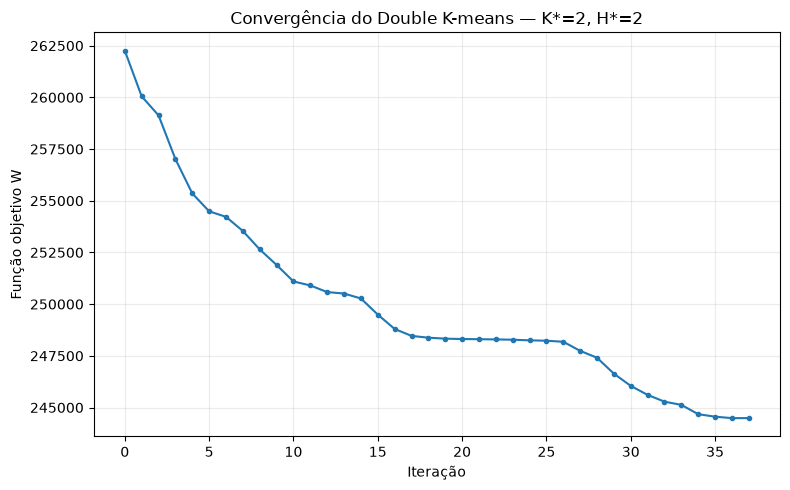

In [11]:

history = np.asarray(best_solution.objective_history)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    np.arange(len(history)),
    history,
    marker="o",
    markersize=3,
)

ax.set_xlabel("Iteração")
ax.set_ylabel("Função objetivo W")
ax.set_title(
    f"Convergência do Double K-means — K*={K_star}, H*={H_star}"
)
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "objetivo_iteracoes.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

print("Número de atualizações:", best_solution.n_iter)
print("W inicial:", history[0])
print("W final:", history[-1])



## 12. Inspecionar os grupos de variáveis

Esta tabela não é obrigatória no enunciado, mas é útil para interpretar
\(H^\*\): ela mostra quais atributos foram agrupados juntos pelo Double
K-means.


In [12]:

variable_partition = pd.DataFrame({
    "feature": feature_names,
    "variable_cluster": best_solution.variable_labels,
}).sort_values(["variable_cluster", "feature"])

display(variable_partition)

variable_partition.to_csv(
    OUTPUT_DIR / "particao_variaveis.csv",
    index=False,
)


                       feature  variable_cluster
33               word_freq_415                 0
27               word_freq_650                 0
34                word_freq_85                 0
31               word_freq_857                 0
39            word_freq_direct                 0
24                word_freq_hp                 0
25               word_freq_hpl                 0
28               word_freq_lab                 0
29              word_freq_labs                 0
35        word_freq_technology                 0
30            word_freq_telnet                 0
54  capital_run_length_average                 1
55  capital_run_length_longest                 1
56    capital_run_length_total                 1
51                 char_freq_!                 1
53                 char_freq_#                 1
52                 char_freq_$                 1
49                 char_freq_(                 1
48                 char_freq_;                 1
50                 c


## 13. Exportar o dataset para a Questão 2

A Questão 2 exige duas versões da variável resposta:

1. `y_original`: spam/non-spam;
2. `y_double_kmeans`: os \(K^\*\) grupos descobertos na Questão 1.

Vamos preservar os atributos **na escala original** no arquivo compartilhado.
A padronização necessária aos classificadores da Questão 2 deve ser feita
dentro do pipeline de validação cruzada deles, evitando vazamento de dados.


In [13]:

q2_df = X_df.copy()
q2_df["y_original"] = y_original
q2_df["y_double_kmeans"] = labels_kstar

q2_path = OUTPUT_DIR / "spambase_com_clusters.csv"
q2_df.to_csv(q2_path, index=False)

display(q2_df.head())

print("Arquivo para o grupo:", q2_path.resolve())
print("\nDistribuição de y_double_kmeans:")
print(q2_df["y_double_kmeans"].value_counts().sort_index())


Arquivo para o grupo: C:\Users\Leticia\.codex\.chatgpt-projects\g-p-6a8591c406b48191ad22905b26a0c44a\questao1_revisada\resultados_questao1_revisada\spambase_com_clusters.csv

Distribuição de y_double_kmeans:
y_double_kmeans
0      34
1    4567
Name: count, dtype: int64


   word_freq_make  word_freq_address  ...  y_original  y_double_kmeans
0            0.00               0.64  ...           1                1
1            0.21               0.28  ...           1                1
2            0.06               0.00  ...           1                1
3            0.00               0.00  ...           1                1
4            0.00               0.00  ...           1                1

[5 rows x 59 columns]


## 14. Arquivo de metadados para o grupo

Além do CSV, vamos registrar exatamente de onde vieram os novos rótulos.


In [14]:

metadata = pd.DataFrame([{
    "K_star": K_star,
    "H_star": H_star,
    "silhouette": float(best_row["silhouette"]),
    "objective_W": float(best_solution.objective),
    "best_seed": int(best_solution.seed),
    "adjusted_rand_index": float(ari),
    "n_restarts_per_KH": N_RESTARTS,
    "scaling_used_for_clustering": "StandardScaler (z-score)",
}])

display(metadata)

metadata.to_csv(
    OUTPUT_DIR / "metadata_para_questao2.csv",
    index=False,
)


   K_star  H_star  ...  n_restarts_per_KH  scaling_used_for_clustering
0       2       2  ...                100     StandardScaler (z-score)

[1 rows x 8 columns]


# Checklist de entrega da Questão 1

Após executar todas as células, compartilhe com o grupo:

- `questao1_double_kmeans.ipynb`;
- `double_kmeans.py`;
- `resultados_questao1/resultados_KH.csv`;
- `resultados_questao1/spambase_com_clusters.csv`;
- `resultados_questao1/metadata_para_questao2.csv`;
- `resultados_questao1/matriz_prototipos_G.csv`;
- `resultados_questao1/matriz_contingencia.csv`;
- `resultados_questao1/silhouette_KH.png`;
- `resultados_questao1/matriz_contingencia.png`;
- `resultados_questao1/objetivo_iteracoes.png`.

## O que dizer ao grupo da Questão 2

O arquivo `spambase_com_clusters.csv` contém:

- os 57 atributos originais;
- `y_original`, com as 2 classes a priori;
- `y_double_kmeans`, com \(K^\*\) classes geradas pela melhor solução da
  Questão 1.

Para a Questão 2:

- **Versão 1:** usar os 57 atributos como `X` e `y_original` como `y`;
- **Versão 2:** usar os mesmos 57 atributos como `X` e
  `y_double_kmeans` como `y`.

Não incluir `y_original` como atributo ao prever `y_double_kmeans`, nem
`y_double_kmeans` como atributo ao prever `y_original`.


## 14. Auditoria de todos os pares (K,H)

O tamanho dos clusters ajuda a interpretar a Silhouette global, que é uma média por objeto: um grupo muito grande tem maior peso. Calculamos a Silhouette Euclidiana no mesmo espaço utilizado no agrupamento. Valores negativos indicam objetos mais próximos, em média, de outro cluster. As caixas mostram a distribuição e os CSVs preservam todos os valores, inclusive extremos.


    K  H  cluster     n  proporcao
0   2  1        0  1018   0.221256
1   2  1        1  3583   0.778744
2   2  2        0    34   0.007390
3   2  2        1  4567   0.992610
4   3  1        0  1187   0.257987
5   3  1        1  3382   0.735058
6   3  1        2    32   0.006955
7   3  2        0  3470   0.754184
8   3  2        1  1097   0.238426
9   3  2        2    34   0.007390
10  3  3        0  3373   0.733101
11  3  3        1  1194   0.259509
12  3  3        2    34   0.007390
13  4  1        0   697   0.151489
14  4  1        1    22   0.004782
15  4  1        2  2242   0.487285
16  4  1        3  1640   0.356444
17  4  2        0  3275   0.711802
18  4  2        1  1049   0.227994
19  4  2        2    24   0.005216
20  4  2        3   253   0.054988
21  4  3        0  1080   0.234732
22  4  3        1   241   0.052380
23  4  3        2  3256   0.707672
24  4  3        3    24   0.005216
25  4  4        0  1037   0.225386
26  4  4        1    29   0.006303
27  4  4        2  3

    K  H  cluster     n  ...       q75       q95    maximo  proporcao_negativa
0   2  1        0  1018  ... -0.184986 -0.062641  0.004915            0.990177
1   2  1        1  3583  ...  0.516213  0.566883  0.577422            0.000000
2   2  2        0    34  ...  0.675077  0.693491  0.693703            0.000000
3   2  2        1  4567  ...  0.727904  0.752765  0.760957            0.000000
4   3  1        0  1187  ... -0.169496 -0.072472 -0.021649            1.000000
5   3  1        1  3382  ...  0.485123  0.539428  0.550726            0.000000
6   3  1        2    32  ...  0.503807  0.507025  0.507053            0.343750
7   3  2        0  3470  ...  0.450229  0.503710  0.514602            0.000000
8   3  2        1  1097  ... -0.141611 -0.058557  0.000114            0.999088
9   3  2        2    34  ...  0.670385  0.688948  0.689165            0.117647
10  3  3        0  3373  ...  0.256210  0.314303  0.328295            0.000000
11  3  3        1  1194  ...  0.000755  0.042070  0.

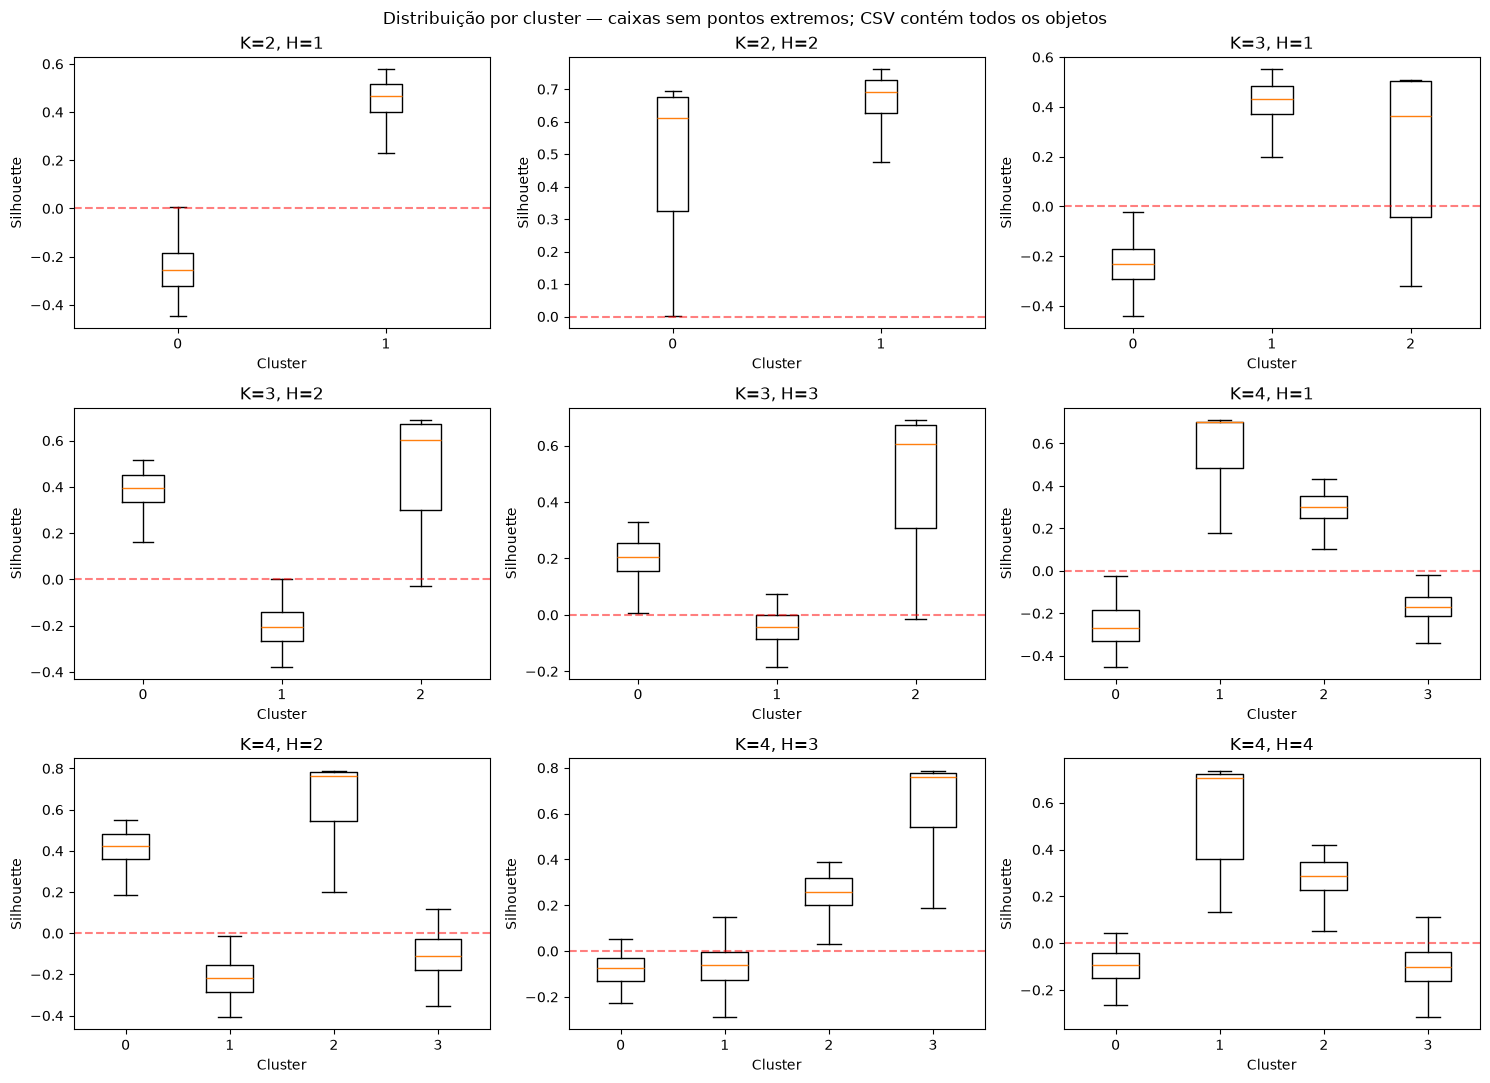

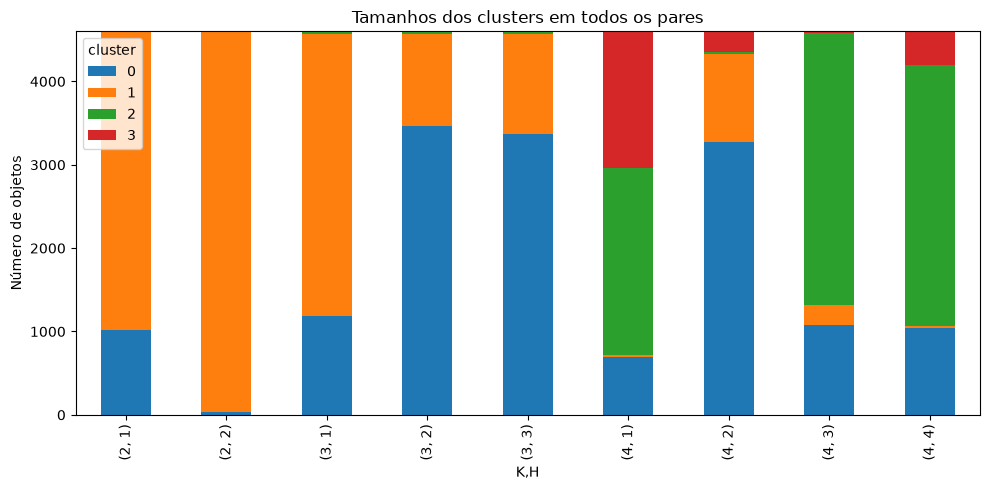

In [15]:
from sklearn.metrics import silhouette_samples
import json
import hashlib
import platform
import sklearn
AUDIT_DIR = OUTPUT_DIR / "auditoria"
AUDIT_DIR.mkdir(exist_ok=True)

# Não supomos que o menor cluster tenha o rótulo 0: rótulos são arbitrários.
size_rows, sil_rows, sample_rows = [], [], []
sil_by_pair = {}
for (K, H), result in best_runs.items():
    labels = result.object_labels
    samples = silhouette_samples(X, labels, metric="euclidean")
    sil_by_pair[(K, H)] = samples
    for k in range(K):
        values = samples[labels == k]
        size_rows.append(dict(K=K, H=H, cluster=k, n=len(values), proporcao=len(values)/len(X)))
        sil_rows.append(dict(K=K, H=H, cluster=k, n=len(values), media=values.mean(),
            mediana=np.median(values), minimo=values.min(), q05=np.quantile(values,.05),
            q25=np.quantile(values,.25), q75=np.quantile(values,.75), q95=np.quantile(values,.95),
            maximo=values.max(), proporcao_negativa=np.mean(values < 0)))
    sample_rows.append(pd.DataFrame(dict(K=K, H=H, objeto_id=np.arange(len(X)),
        linha_spambase=np.arange(1,len(X)+1), cluster=labels, silhouette=samples)))
sizes = pd.DataFrame(size_rows)
sil_summary = pd.DataFrame(sil_rows)
sizes.to_csv(AUDIT_DIR / "tamanhos_todos_KH.csv", index=False)
sil_summary.to_csv(AUDIT_DIR / "silhouette_por_cluster.csv", index=False)
pd.concat(sample_rows).to_csv(AUDIT_DIR / "silhouette_por_objeto_todos_KH.csv", index=False)
display(sizes)
display(sil_summary)
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, ((K,H), result) in zip(axes.flat, best_runs.items()):
    values = sil_by_pair[(K,H)]
    ax.boxplot([values[result.object_labels==k] for k in range(K)], tick_labels=range(K), showfliers=False)
    ax.axhline(0, color='red', linestyle='--', alpha=.5)
    ax.set_title(f"K={K}, H={H}")
    ax.set_xlabel("Cluster"); ax.set_ylabel("Silhouette")
fig.suptitle("Distribuição por cluster — caixas sem pontos extremos; CSV contém todos os objetos")
fig.tight_layout(); fig.savefig(AUDIT_DIR / "silhouette_distribuicoes.png", dpi=160); plt.show()
fig, ax = plt.subplots(figsize=(10,5))
sizes.pivot(index=['K','H'], columns='cluster', values='n').plot.bar(stacked=True, ax=ax)
ax.set_ylabel('Número de objetos'); ax.set_title('Tamanhos dos clusters em todos os pares')
fig.tight_layout(); fig.savefig(AUDIT_DIR / 'tamanhos_clusters.png', dpi=160); plt.show()


## 15. Os 34 objetos e as variáveis que os distinguem

Identificamos o menor grupo automaticamente. `objeto_id` começa em 0; `linha_spambase` começa em 1 e aponta para a linha do arquivo sem cabeçalho. Exportamos os 57 atributos, classe original, Silhouette individual e medidas de valores extremos no espaço z-score. Esses indicadores descrevem o grupo; não autorizam excluir observações como “outliers”.

O ranking compara o grupo pequeno com o restante em escala original e padroniza a diferença pelo desvio global. Medianas e frequências de valores não zero ajudam a distinguir diferenças gerais de diferenças concentradas em poucos valores. O ranking de eta² complementa a análise caso o vencedor tenha mais de dois clusters. As classes originais nunca entram na otimização.


Cluster pequeno: 0; n=34; proporção=0.7390%
Classes: {0: 34}
Objetos do grupo que têm duplicatas na base: 8


      objeto_id  ...  distancia_centro_global_z
1818       1818  ...                  16.030610
1878       1878  ...                  19.120645
1922       1922  ...                  19.120575
1964       1964  ...                  33.738428
2053       2053  ...                  26.431435
2150       2150  ...                  13.506231
2270       2270  ...                  30.877920
2327       2327  ...                  17.264967
2554       2554  ...                  16.981782
2574       2574  ...                  35.412518
2630       2630  ...                  35.412518
2673       2673  ...                  22.303704
2696       2696  ...                  35.412518
2848       2848  ...                  32.247068
2915       2915  ...                  23.067466
2974       2974  ...                  20.137253
3019       3019  ...                  12.593663
3020       3020  ...                  12.593663
3157       3157  ...                  14.818126
3245       3245  ...                  35

                    variavel  ...  abs_diferenca_padronizada
31             word_freq_857  ...                   9.577703
33             word_freq_415  ...                   9.549525
39          word_freq_direct  ...                   8.807262
30          word_freq_telnet  ...                   8.164428
35      word_freq_technology  ...                   8.098140
29            word_freq_labs  ...                   7.257466
34              word_freq_85  ...                   6.110743
27             word_freq_650  ...                   6.002725
28             word_freq_lab  ...                   5.275079
24              word_freq_hp  ...                   3.706516
25             word_freq_hpl  ...                   3.485320
49               char_freq_(  ...                   2.845391
18             word_freq_you  ...                   0.743759
26          word_freq_george  ...                   0.705025
20            word_freq_your  ...                   0.564192
2              word_freq

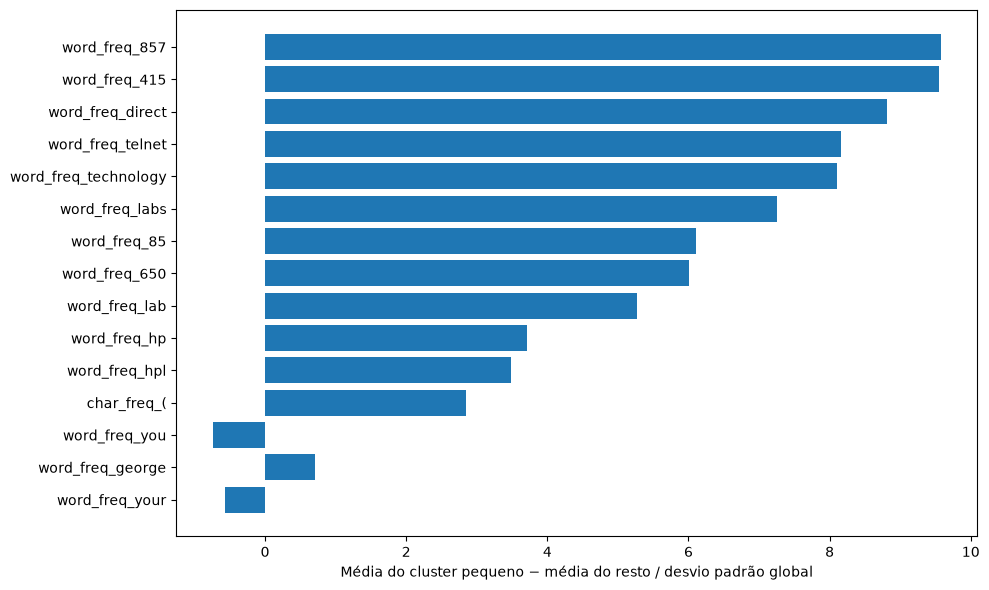

In [16]:
counts = pd.Series(labels_kstar).value_counts()
small_label = int(counts.idxmin())
mask = labels_kstar == small_label
winner_sil = sil_by_pair[(K_star,H_star)]
z_original = StandardScaler().fit_transform(X_original)
small_objects = X_df.loc[mask].copy()
small_objects.insert(0, 'objeto_id', np.flatnonzero(mask))
small_objects.insert(1, 'linha_spambase', np.flatnonzero(mask)+1)
small_objects['y_original'] = y_original[mask]
small_objects['cluster'] = labels_kstar[mask]
small_objects['silhouette'] = winner_sil[mask]
small_objects['max_abs_z'] = np.abs(z_original[mask]).max(axis=1)
small_objects['n_atributos_abs_z_maior_3'] = (np.abs(z_original[mask]) > 3).sum(axis=1)
small_objects['distancia_centro_global_z'] = np.linalg.norm(z_original[mask], axis=1)
small_objects['tem_duplicata_atributos_na_base'] = X_df.duplicated(keep=False).to_numpy()[mask]
small_objects.to_csv(AUDIT_DIR / 'objetos_cluster_pequeno.csv', index=False)
small_objects[feature_names].describe().T.to_csv(AUDIT_DIR / 'descritivas_cluster_pequeno.csv')
pd.crosstab(labels_kstar, y_original).to_csv(AUDIT_DIR / 'classes_por_cluster.csv')
duplicates = X_df.duplicated(keep=False).to_numpy()
print(f'Cluster pequeno: {small_label}; n={mask.sum()}; proporção={mask.mean():.4%}')
print('Classes:', pd.Series(y_original[mask]).value_counts().to_dict())
print('Objetos do grupo que têm duplicatas na base:', int(duplicates[mask].sum()))
if REUTILIZAR_ZIP:
    assert mask.sum() == 34, 'A solução do ZIP deveria ter 34 objetos no menor cluster.'
display(small_objects)

# Diferença de médias em unidades do desvio padrão GLOBAL (ddof=0).
# Não é teste de hipótese nem prova de causalidade; descreve esta partição.
std = X_original.std(axis=0)
delta = X_original[mask].mean(axis=0)-X_original[~mask].mean(axis=0)
ranking = pd.DataFrame(dict(variavel=feature_names,
    media_pequeno=X_original[mask].mean(axis=0), media_resto=X_original[~mask].mean(axis=0),
    mediana_pequeno=np.median(X_original[mask],axis=0), mediana_resto=np.median(X_original[~mask],axis=0),
    prop_nao_zero_pequeno=(X_original[mask]!=0).mean(axis=0),
    prop_nao_zero_resto=(X_original[~mask]!=0).mean(axis=0),
    diferenca_media=delta, desvio_global=std,
    diferenca_padronizada=np.divide(delta,std,out=np.zeros_like(delta),where=std>0)))
ranking['abs_diferenca_padronizada'] = ranking.diferenca_padronizada.abs()
ranking = ranking.sort_values('abs_diferenca_padronizada',ascending=False)
ranking.to_csv(AUDIT_DIR / 'ranking_variaveis_pequeno_vs_resto.csv',index=False)
# Ranking complementar para K>2: dispersão das médias entre TODOS os clusters.
means = np.vstack([X_original[labels_kstar==k].mean(axis=0) for k in range(K_star)])
weights = np.bincount(labels_kstar,minlength=K_star)/len(X)
between = (weights[:,None]*(means-X_original.mean(axis=0))**2).sum(axis=0)
eta2 = np.divide(between,std**2,out=np.zeros_like(between),where=std>0)
pd.DataFrame({'variavel':feature_names,'eta_quadrado':eta2}).sort_values('eta_quadrado',ascending=False).to_csv(AUDIT_DIR/'ranking_todos_clusters.csv',index=False)
display(ranking.head(20))
fig, ax = plt.subplots(figsize=(10,6))
top = ranking.head(15).iloc[::-1]
ax.barh(top.variavel, top.diferenca_padronizada)
ax.set_xlabel('Média do cluster pequeno − média do resto / desvio padrão global')
fig.tight_layout(); fig.savefig(AUDIT_DIR/'ranking_variaveis.png',dpi=160); plt.show()


## 16. Sensibilidade ao pré-processamento

Comparamos dados originais, StandardScaler e log1p seguido de StandardScaler para os mesmos nove pares e a mesma sequência de seeds. Em cada par, selecionamos a menor W entre 100 execuções válidas; só depois calculamos a Silhouette. Rejeições por clusters vazios são registradas. O limite de tentativas evita loops intermináveis.

**Interpretação:** W em escalas diferentes não é diretamente comparável. A Silhouette no próprio espaço também usa geometrias diferentes: uma melhora não prova que um pré-processamento é melhor. Incluímos a Silhouette das três partições no espaço StandardScaler como referência comum, tamanhos e ARI entre partições. O ARI com spam/non-spam é uma avaliação externa, não um critério para escolher pré-processamento.

log1p é aplicada aos 57 atributos não negativos e reduz a assimetria, mas altera distâncias e a interpretação dos blocos de variáveis. A decisão metodológica deve ser justificada e alinhada com o professor. Esta célula pode levar vários minutos. Se falhar, corrija a causa e execute novamente; um grid incompleto não produz conclusão.


Sensibilidade: originais, K=2, H=1
Sensibilidade: originais, K=2, H=2
Sensibilidade: originais, K=3, H=1
Sensibilidade: originais, K=3, H=2
Sensibilidade: originais, K=3, H=3
Sensibilidade: originais, K=4, H=1
Sensibilidade: originais, K=4, H=2
Sensibilidade: originais, K=4, H=3
Sensibilidade: originais, K=4, H=4
Sensibilidade: log1p_standard, K=2, H=1
Sensibilidade: log1p_standard, K=2, H=2
Sensibilidade: log1p_standard, K=3, H=1
Sensibilidade: log1p_standard, K=3, H=2
Sensibilidade: log1p_standard, K=3, H=3
Sensibilidade: log1p_standard, K=4, H=1
Sensibilidade: log1p_standard, K=4, H=2
Sensibilidade: log1p_standard, K=4, H=3
Sensibilidade: log1p_standard, K=4, H=4
Diagnósticos exportados para C:\Users\Leticia\.codex\.chatgpt-projects\g-p-6a8591c406b48191ad22905b26a0c44a\questao1_revisada\resultados_questao1_revisada


  preprocessamento  K_star  ...  proporcao_menor             W
0         standard       2  ...         0.007390  2.444867e+05
1        originais       2  ...         0.051728  2.219683e+09
2   log1p_standard       2  ...         0.038253  2.421164e+05

[3 rows x 11 columns]

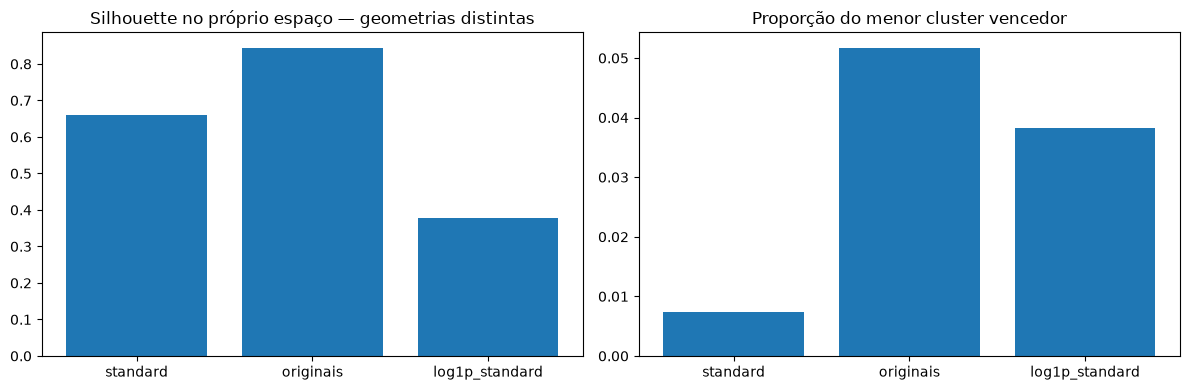

In [17]:
from itertools import combinations
SENS_DIR = OUTPUT_DIR / 'sensibilidade'
SENS_DIR.mkdir(exist_ok=True)
assert np.all(X_original >= 0), 'log1p exige verificar o domínio dos atributos.'
spaces = {'originais': X_original,
          'standard': X,
          'log1p_standard': StandardScaler().fit_transform(np.log1p(X_original))}
all_solutions = {'standard': best_runs}
tables = {'standard': results_df.copy()}
convergence_rows = []
for mode, Xm in spaces.items():
    if mode == 'standard':
        continue
    rows, solutions = [], {}
    for K in [2,3,4]:
        for H in range(1,K+1):
            print(f'Sensibilidade: {mode}, K={K}, H={H}', flush=True)
            exp = run_restarts(Xm,K,H,N_RESTARTS,RANDOM_BASE_SEED,MAX_ITER)
            result = exp['best']
            solutions[(K,H)] = result
            rows.append(dict(K=K,H=H,best_objective_W=result.objective,
                silhouette=silhouette_score(Xm,result.object_labels),best_seed=result.seed,
                n_iterations_best=result.n_iter,valid_runs=exp['valid_runs'],
                invalid_attempts=exp['invalid_runs'],total_attempts=exp['attempts']))
    all_solutions[mode] = solutions
    tables[mode] = pd.DataFrame(rows)

comparison, size_sens, winners = [], [], {}
for mode, table in tables.items():
    table.to_csv(SENS_DIR/f'grid_{mode}.csv',index=False)
    win = table.loc[table.silhouette.idxmax()]
    key = (int(win.K),int(win.H))
    winners[mode] = all_solutions[mode][key].object_labels
    for (K,H), result in all_solutions[mode].items():
        sizes_mode = np.bincount(result.object_labels,minlength=K)
        for k,n in enumerate(sizes_mode):
            size_sens.append(dict(preprocessamento=mode,K=K,H=H,cluster=k,n=n,proporcao=n/len(X)))
        # Atingir MAX_ITER não prova convergência; registramos isso explicitamente.
        convergence_rows.append(dict(preprocessamento=mode,K=K,H=H,
            atingiu_limite=result.n_iter>=MAX_ITER,seed=result.seed))
        np.savez_compressed(SENS_DIR/f'particao_{mode}_K{K}_H{H}.npz',
            object_labels=result.object_labels,variable_labels=result.variable_labels,
            G=result.G,objective_history=result.objective_history,seed=result.seed)
    labels = winners[mode]
    ns = np.bincount(labels)
    # Silhouette em StandardScaler é uma referência comum para as três partições.
    comparison.append(dict(preprocessamento=mode,K_star=key[0],H_star=key[1],
        silhouette_no_proprio_espaco=float(win.silhouette),
        silhouette_no_espaco_standard=silhouette_score(X,labels),
        ARI_classes=adjusted_rand_score(y_original,labels),
        ARI_vencedor_zip=adjusted_rand_score(labels_kstar,labels),
        menor_cluster=int(ns.min()),maior_cluster=int(ns.max()),
        proporcao_menor=ns.min()/len(X),W=float(win.best_objective_W)))
    frame = X_df.copy(); frame['y_original']=y_original; frame['cluster_diagnostico']=labels
    frame.to_csv(SENS_DIR/f'rotulos_diagnostico_{mode}.csv',index=False)
    pd.crosstab(labels,y_original).to_csv(SENS_DIR/f'contingencia_{mode}.csv')
summary_sens = pd.DataFrame(comparison)
summary_sens.to_csv(SENS_DIR/'comparacao_vencedores.csv',index=False)
pd.DataFrame(size_sens).to_csv(SENS_DIR/'tamanhos_todos_preprocessamentos.csv',index=False)
pd.DataFrame(convergence_rows).to_csv(SENS_DIR/'convergencia_melhores_solucoes.csv',index=False)
# ARI não depende de como os números dos rótulos foram permutados.
stability = []
for a,b in combinations(spaces,2):
    stability.append(dict(modo_a=a,modo_b=b,tipo='vencedores',K=np.nan,H=np.nan,
        ARI=adjusted_rand_score(winners[a],winners[b])))
    for K,H in best_runs:
        stability.append(dict(modo_a=a,modo_b=b,tipo='mesmo_KH',K=K,H=H,
            ARI=adjusted_rand_score(all_solutions[a][(K,H)].object_labels,
                                    all_solutions[b][(K,H)].object_labels)))
pd.DataFrame(stability).to_csv(SENS_DIR/'estabilidade_particoes_ARI.csv',index=False)
display(summary_sens)
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].bar(summary_sens.preprocessamento,summary_sens.silhouette_no_proprio_espaco)
axes[0].set_title('Silhouette no próprio espaço — geometrias distintas')
axes[1].bar(summary_sens.preprocessamento,summary_sens.proporcao_menor)
axes[1].set_title('Proporção do menor cluster vencedor')
fig.tight_layout(); fig.savefig(SENS_DIR/'comparacao_preprocessamentos.png',dpi=160); plt.show()
manifest = dict(python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,
    sklearn=sklearn.__version__,n_restarts=N_RESTARTS,max_iter=MAX_ITER,base_seed=RANDOM_BASE_SEED,
    standard_reutiliza_zip=REUTILIZAR_ZIP,
    sha256_dados=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    sha256_algoritmo=hashlib.sha256(Path('double_kmeans.py').read_bytes()).hexdigest())
(OUTPUT_DIR/'manifesto_execucao.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Diagnósticos exportados para',OUTPUT_DIR.resolve())


## 17. Como usar os diagnósticos no relatório e na Questão 2

1. Conferir a reprodução do ZIP e os tamanhos de todos os pares. Uma função objetivo não crescente é uma verificação de sanidade, não uma prova completa de ausência de bugs.
2. Descrever os 34 objetos usando os IDs, as classes, medianas, frequências e o ranking; evitar chamar o grupo de erro ou excluir seus objetos sem justificativa.
3. Comparar tamanho do menor grupo, Silhouette, estabilidade das partições e concordância externa nos três pré-processamentos. Verificar soluções que atingiram o limite de iterações.
4. Incorporar a resposta do professor antes de definir qual versão gera os rótulos oficiais para a Questão 2. Os arquivos `rotulos_diagnostico_*` são experimentais; o CSV principal mantém a solução StandardScaler original.
5. Na Questão 2, qualquer transformação dos atributos deve ser ajustada somente nos dados de treinamento de cada divisão da validação cruzada.


## 18. Interpretação dos resultados executados nesta revisão

| Pré-processamento | Par vencedor | Tamanhos | Silhouette no próprio espaço | ARI com as classes |
|---|---|---|---|---|
| StandardScaler | (2,2) | 34 / 4567 | 0,6596 | −0,00495 |
| Dados originais | (2,1) | 238 / 4363 | 0,8444 | 0,04218 |
| log1p + StandardScaler | (2,2) | 176 / 4425 | 0,3791 | −0,02079 |

Os números acima correspondem à execução entregue. Se alterar os dados ou os parâmetros, use as tabelas recalculadas na seção 16 para atualizar esta interpretação.

**Conclusões:** o pré-processamento altera a partição e o tamanho do grupo pequeno; as três alternativas continuam desbalanceadas e não reproduzem bem spam/non-spam. A Silhouette de 0,8444 nos dados originais não demonstra superioridade metodológica. Quando avaliadas no mesmo espaço StandardScaler, as partições original, StandardScaler e log1p+StandardScaler têm Silhouette de 0,1708, 0,6596 e 0,3646, respectivamente. Essa referência comum também é uma escolha de geometria, não um critério definitivo.

Na auditoria StandardScaler, oito dos nove pares têm algum cluster com menos de 1% dos objetos. Os 34 objetos do vencedor pertencem à classe 0. Oito deles têm duplicatas exatas de atributos na base; isso merece registro, mas não justifica removê-los automaticamente. Os maiores contrastes padronizados são word_freq_857 (9,58), word_freq_415 (9,55), word_freq_direct (8,81), word_freq_telnet (8,16) e word_freq_technology (8,10).

Nenhuma das 27 melhores soluções atingiu o limite de 200 iterações nesta execução. Reproduzimos as nove melhores soluções do ZIP e executamos 1800 novas execuções válidas na sensibilidade, com o mesmo algoritmo. Isso apoia a consistência dos resultados, sem substituir a revisão metodológica com o professor. O CSV principal para a Questão 2 preserva a solução original; as alternativas ficam separadas como diagnósticos.
